In [1]:
import torch
import torch.nn as nn
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import timm
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
base_model = timm.create_model('efficientnet_b0', pretrained=True)
features_model = nn.Sequential(*list(base_model.children())[:-1]).to(device)
features_model.eval()

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (1): BatchNormAct2d(
    32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
    (drop): Identity()
    (act): SiLU(inplace=True)
  )
  (2): Sequential(
    (0): Sequential(
      (0): DepthwiseSeparableConv(
        (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn1): BatchNormAct2d(
          32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): SiLU(inplace=True)
        )
        (aa): Identity()
        (se): SqueezeExcite(
          (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (act1): SiLU(inplace=True)
          (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (gate): Sigmoid()
        )
        (conv_pw): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn2): BatchNormAct2d

In [4]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [23]:
train_dataset = datasets.ImageFolder(root='./archieve/train', transform=transform)
test_dataset = datasets.ImageFolder(root='./archieve/train', transform=transform)

In [24]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

In [25]:
def extract_features(model, data_loader):
    features_list = []
    labels_list = []
    
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            output = model(images)
            output = torch.flatten(output, start_dim=1)
            
            features_list.append(output.cpu().numpy())
            labels_list.append(labels.numpy())
            
    X = np.concatenate(features_list, axis=0)
    y = np.concatenate(labels_list, axis=0)
    return X, y

In [26]:
X_train, y_train = extract_features(features_model, train_loader)
X_test, y_test = extract_features(features_model, test_loader)

X_train_norm = X_train / np.linalg.norm(X_train, axis=1, keepdims=True)
X_test_norm = X_test / np.linalg.norm(X_test, axis=1, keepdims=True)

k = 5
y_pred = []

for test_vec in X_test_norm:
    similarities = np.dot(X_train_norm, test_vec)
    top_k_indices = np.argsort(similarities)[-k:]
    top_k_labels = y_train[top_k_indices]
    most_common_label = np.bincount(top_k_labels).argmax()
    y_pred.append(most_common_label)

y_pred = np.array(y_pred)

target_names = train_dataset.classes

print(classification_report(y_test, y_pred, target_names=target_names))

cm = confusion_matrix(y_test, y_pred)

                   precision    recall  f1-score   support

     ace of clubs       0.59      0.88      0.70       120
  ace of diamonds       0.63      0.81      0.71       129
    ace of hearts       0.68      0.74      0.71       171
    ace of spades       0.68      0.92      0.78       181
   eight of clubs       0.36      0.70      0.48       138
eight of diamonds       0.38      0.70      0.49       159
  eight of hearts       0.37      0.72      0.49       152
  eight of spades       0.37      0.55      0.44       135
    five of clubs       0.41      0.73      0.52       150
 five of diamonds       0.44      0.62      0.52       138
   five of hearts       0.49      0.59      0.54       136
   five of spades       0.46      0.58      0.51       158
    four of clubs       0.54      0.47      0.50       157
 four of diamonds       0.51      0.46      0.49       114
   four of hearts       0.48      0.44      0.45       154
   four of spades       0.67      0.62      0.65       

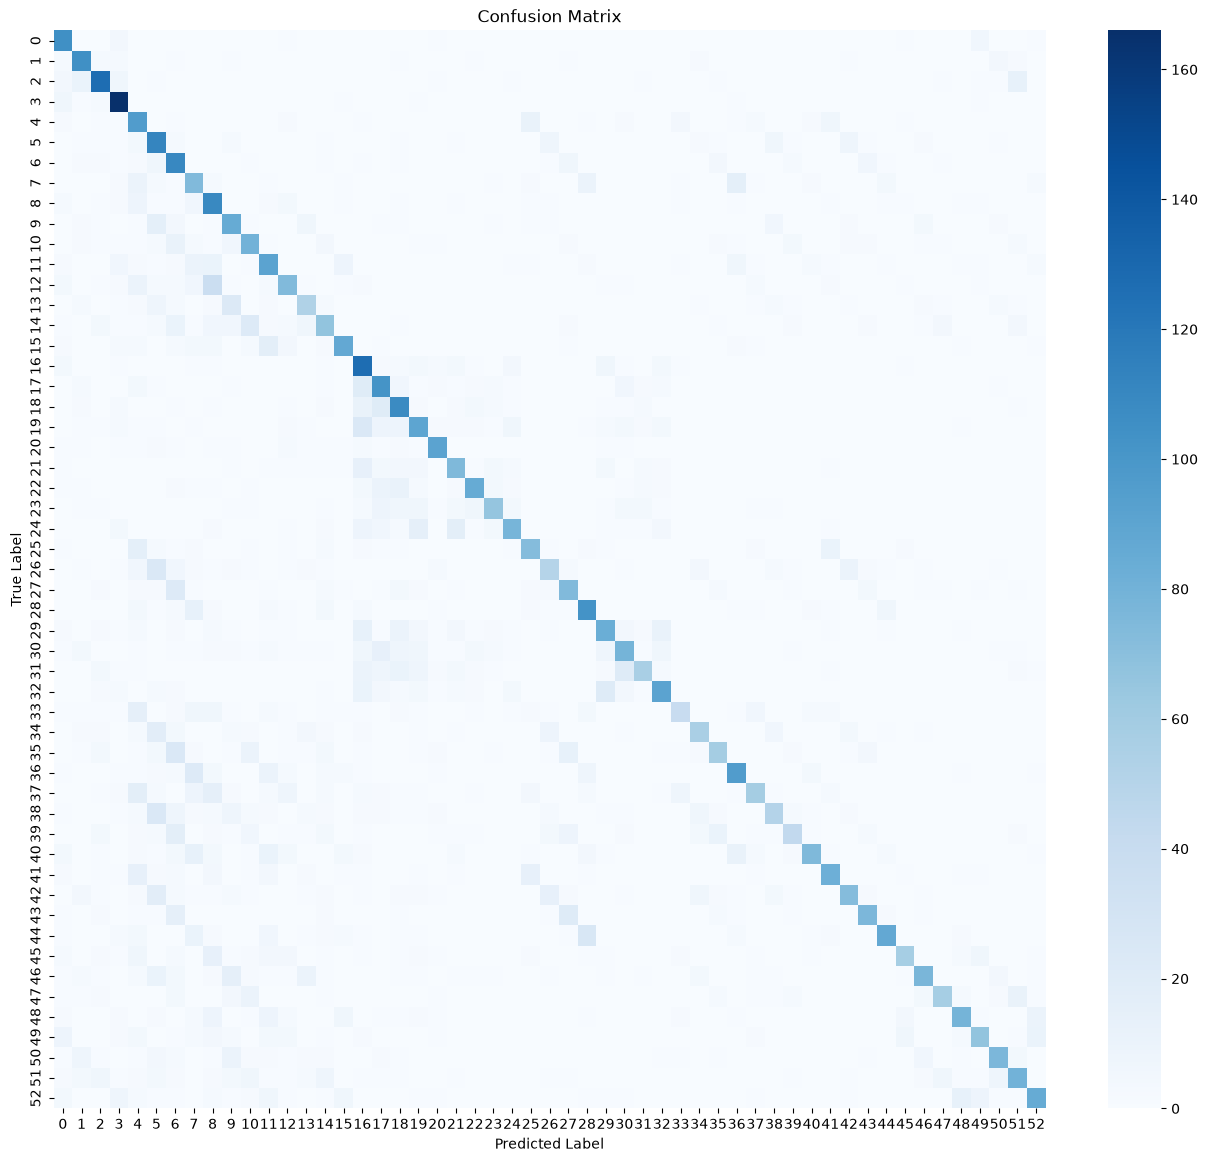

In [27]:
plt.figure(figsize=(16, 14))
sns.heatmap(cm, annot=False, cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()